# GridSFM — Feasibility-aware Gaussian Pd/Qd sampling with early stopping

**Notebook 1 of 2 — load perturbations only.** This is your original notebook with a targeted update: monitor the Julia AC-OPF acceptance rate, keep the **best evaluated proposal Gaussian** (mean + full covariance), stop when the rate does not improve, and then draw a **fresh independent batch from the best Gaussian** for future GridSFM / SHAP / Captum analysis.

- Input: `power_grid/US/gridsfm_data/<time_slice>/<dataset>_model.json`
- Verifier: existing `verifier/acopf_verifier.jl`, **unchanged**
- Training archive: `results/gaussian_load_centered/<dataset>/acopf_labeled_scenarios.npz`
- Best parameters: `.../best_gaussian_parameters.npz`
- **Fresh labeled explanation batch**: `.../acopf_best_gaussian_explanations.npz`

**Important:** The best parameters are saved **before** each accepted-noise update, because those are the ones that actually produced the measured acceptance rate. A solver result of `NOT_VERIFIED` is not a proof of physical infeasibility. Small batches give noisy acceptance-rate estimates, so the selected Gaussian is the best **observed** one, not a guaranteed global optimum. Avoid rerunning the adaptive-loop cell without first rerunning the initialization cell.


## 1. Imports, dataset selection, and Julia verifier

Choose `DATASET_NAME` and `TIME_SLICE`. Find the repository root from the current working directory (supports running Jupyter from `GridSFM/`, `GridSFM/notebook/`, or the parent containing `GridSFM/`). The grid dataset can be inside the repository or in a sibling `power_grid/` folder. If your layout is different, edit `DATA_DIR` directly.


In [12]:
import copy
import csv
import hashlib
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from juliacall import Main as jl


In [13]:
DATASET_NAME = "alabama"    # Same as load notebook; use "texas" if preferred
TIME_SLICE = "16h"
DATA_DIR = Path("../power_grid/US/gridsfm_data") / TIME_SLICE
DATA_PATH = DATA_DIR / f"{DATASET_NAME}_model.json"
JULIA_SCRIPT = Path("../verifier/acopf_verifier.jl")
OUTPUT_DIR = Path("../results/gaussian_load_centered") / "results" / "gaussian_voltage_squeeze" / DATASET_NAME
SCENARIO_PATH = OUTPUT_DIR / "acopf_labeled_scenarios.npz"
BEST_PARAMS_PATH = OUTPUT_DIR / "best_gaussian_parameters.npz"
BEST_EXPLAIN_PATH = OUTPUT_DIR / "acopf_best_gaussian_explanations.npz"

DATASET_LABEL = DATASET_NAME.replace("_", " ").title()
assert DATA_PATH.is_file(), f"Grid case not found: {DATA_PATH}; checked {_data_dirs}"
assert JULIA_SCRIPT.is_file(), f"Julia verifier not found: {JULIA_SCRIPT}"
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
assert isinstance(data.get("bus"), dict), "Expected case with a 'bus' dictionary"
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_LABEL, "| Case:", DATA_PATH)
print("Julia verifier:", JULIA_SCRIPT)
print("Output directory:", OUTPUT_DIR)
print("Buses:", len(data["bus"]), "| baseMVA:", data.get("baseMVA"))


Dataset: Alabama | Case: ../power_grid/US/gridsfm_data/16h/alabama_model.json
Julia verifier: ../verifier/acopf_verifier.jl
Output directory: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama
Buses: 494 | baseMVA: 100.0


## 2. Preserve mapping between Python load rows and Julia load IDs

In [14]:
# Preserve load IDs so we can map samples back
load_ids = []
for load_id, load in data["load"].items():
    if load["status"] == 1:
        load_ids.append(load_id)

# Original load dataset: columns [Pd, Qd]
loads = []
for load_id in load_ids:
    loads.append([
        data["load"][load_id]["pd"],
        data["load"][load_id]["qd"]
    ])

loads = np.array(loads, dtype=float)
n_loads = len(load_ids)

assert n_loads >= 2, "This Gaussian covariance requires at least two active loads."
assert loads.shape == (n_loads, 2) and np.isfinite(loads).all()

print("Active loads:", n_loads, "| Shape:", loads.shape)
print("Original mean [Pd,Qd]:", loads.mean(axis=0), "| Base MVA:", data.get("baseMVA"))
print("Original total [Pd,Qd] (p.u.):", loads.sum(axis=0), "| Base MVA:", data.get("baseMVA"))


Active loads: 494 | Shape: (494, 2)
Original mean [Pd,Qd]: [0.19233127 0.08193278] | Base MVA: 100.0
Original total [Pd,Qd] (p.u.): [95.011645   40.47479128] | Base MVA: 100.0


## 3. Initialize the existing PowerModels AC-OPF verifier for this case

This notebook invokes the verifier's **load-only** compatibility method, `verify_loads_json`. The general all-modes Julia verifier supports this method as well. Initialization registers active load IDs in the **same order** as the Python `loads` matrix.


In [15]:
jl.include(str(JULIA_SCRIPT.resolve()))
summary_text = jl.GridSFMLoadVerifier.initialize_case(
    str(DATA_PATH.resolve()), json.dumps(load_ids)
)
print("Julia case initialized:\n", json.loads(str(summary_text)))


Julia case initialized:
 {'n_buses': 494, 'baseMVA': 100.0, 'supported_modes': ['branch', 'bus', 'gen', 'load'], 'initialized': True, 'n_loads': 494, 'n_generators': 55, 'n_total_loads': 494, 'n_branches': 864, 'per_unit': True}


## 4. Python wrapper and baseline AC-OPF check

`accepted=True` requires the Julia verifier's strict solver criteria. Before sampling, check that the **selected dataset's original case** can be accepted by the solver. A failed solve is reported as not verified; it does not prove network infeasibility. The baseline guard is intentionally unchanged.


In [16]:
def verify_acopf(candidate_loads):
    """Pass an (n_loads,2) absolute per-unit load matrix to Julia PowerModels."""
    start = time.perf_counter()
    values = np.asarray(candidate_loads, dtype=float)
    if values.shape != loads.shape or not np.isfinite(values).all():
        return {"accepted": False, "status": "INVALID_INPUT", "objective": None,
                "reason": f"Expected finite shape {loads.shape}; got {values.shape}",
                "termination_status": "NOT_RUN", "primal_status": "UNKNOWN",
                "elapsed_s": time.perf_counter() - start}
    try:
        raw = jl.GridSFMLoadVerifier.verify_loads_json(json.dumps(values.tolist()))
        result = json.loads(str(raw))
        result["elapsed_s"] = time.perf_counter() - start
        return result
    except Exception as exc:
        return {"accepted": False, "status": "SOLVER_ERROR", "objective": None,
                "reason": str(exc)[:1000], "termination_status": "ERROR",
                "primal_status": "UNKNOWN", "elapsed_s": time.perf_counter() - start}


In [17]:
print(f"Verifying the original {DATASET_LABEL} case")
baseline_result = verify_acopf(loads)
print("Baseline:\n", baseline_result)
if not baseline_result["accepted"]:
    raise RuntimeError("Baseline not confirmed: " + str(baseline_result))

Verifying the original Alabama case
Baseline:
 {'stage': 'opf', 'modes': ['load'], 'termination_status': 'LOCALLY_SOLVED', 'objective': 198538.08988997107, 'primal_status': 'FEASIBLE_POINT', 'reason': '', 'warnings': [], 'applied_components': {'load': 494}, 'solve_time': 0.652108907699585, 'accepted': True, 'status': 'OPF_SOLVED', 'elapsed_s': 1.211812417008332}


## 5. Initialize the **additive noise Gaussian** from original data

`base_cov = np.cov(loads, rowvar=False, bias=True)` is calculated directly from the selected dataset’s load `[Pd,Qd]`; it is **not** a covariance of multipliers. Gaussian noise is scaled by `INITIAL_SCALE²`.

Formula: `candidate_loads[i] = original_loads[i] + noise[i]`. Adaptive `noise_mu` and `noise_cov` describe perturbations, **not pooled absolute load values**.


In [18]:
SEED = 42
iterations = 10                  # Maximum adaptive iterations (early stopping may end sooner)
samples_per_iteration = 2       # Set e.g. 10+ for less noisy acceptance-rate estimates
alpha = 0.30                    # Accepted-noise exponential smoothing
INITIAL_SCALE = 1.5            # Initial standard deviation is scaled by this factor
NONNEGATIVE = True             # Redraw any [Pd,Qd] pair containing negative values
MAX_RESAMPLE_ROUNDS = 1000
COV_REG = 1e-10                 # Tiny diagonal regularization

# Early stopping + fresh explanation batch.
EARLY_STOP_PATIENCE = 3         # Stop after this many consecutive non-improving batches
EARLY_STOP_MIN_DELTA = 0.0      # Improvement must exceed this fraction (0 => strictly higher)
FINAL_EXPLAIN_SCENARIOS = samples_per_iteration  # Fresh AC-OPF solves after training
FINAL_EXPLAIN_SEED = SEED + 100_003              # Independent of training RNG

assert iterations >= 1 and samples_per_iteration >= 1
assert EARLY_STOP_PATIENCE >= 1 and FINAL_EXPLAIN_SCENARIOS >= 1
assert 0 <= EARLY_STOP_MIN_DELTA < 1

rng = np.random.default_rng(SEED)
base_cov = np.cov(loads, rowvar=False, bias=True)
base_cov = 0.5 * (base_cov + base_cov.T)
noise_mu = np.zeros(2)  # Initial perturbations are centered at the original loads.
noise_cov = (INITIAL_SCALE ** 2) * base_cov + np.eye(2) * COV_REG
initial_noise_mu = noise_mu.copy()
initial_noise_cov = noise_cov.copy()

history = []             # One Gaussian/acceptance summary per completed iteration
verification_log = []    # Every training scenario's Julia result
explain_candidates = []  # All training proposals, accepted AND not accepted
explain_labels = []      # 1 = Julia accepted; 0 = not accepted (may include solver failures)
explain_metadata = []    # Iteration, scenario, status, termination status

# NEW: These parameters belong to the best-performing EVALUATED proposal Gaussian.
best_rate = -1.0
best_iteration = None
best_noise_mu = None
best_noise_cov = None
no_improve = 0

print("Original data covariance:\n", base_cov)
print("Initial noise mean:", noise_mu)
print("Initial noise std:", np.sqrt(np.diag(noise_cov)))
print("Maximum training proposals:", iterations * samples_per_iteration)
print("Fresh explanation proposals:", FINAL_EXPLAIN_SCENARIOS)
print("Early stopping: patience", EARLY_STOP_PATIENCE,
      "| improvement threshold", EARLY_STOP_MIN_DELTA)


Original data covariance:
 [[0.00635228 0.00270606]
 [0.00270606 0.00115278]]
Initial noise mean: [0. 0.]
Initial noise std: [0.11955181 0.05092886]
Maximum training proposals: 20
Fresh explanation proposals: 2
Early stopping: patience 3 | improvement threshold 0.0


## 7. Load-centered Gaussian sampler with optional nonnegative pair rejection

Every load has its own center (`loads[i]`). When a pair contains a negative Pd **or** Qd, redraw **the entire noise pair** for that load. This preserves Pd–Qd dependence *within a joint conditional sample*, but the resulting truncated distribution is no longer an unconstrained Gaussian. Failure to draw valid pairs within the limit raises a clear error instead of silently clipping.

In [19]:
def sample_load_centered_gaussian(rng, loads, noise_mu, noise_cov,
                                  n_scenarios, nonnegative=True,
                                  max_rounds=1000):
    """Return proposed absolute loads, realized noise, and draw diagnostics."""
    n = len(loads)
    noise = rng.multivariate_normal(noise_mu, noise_cov, size=(n_scenarios, n),
                                    check_valid="raise")
    candidates = loads[None, :, :] + noise
    initial_invalid = int(np.any(candidates < 0, axis=-1).sum()) # count how many load pairs have negative Pd or Qd values immediately after the first Gaussian sampling, before any resampling happens
    rounds, total_redraws = 0, 0
    if nonnegative:
        invalid = np.any(candidates < 0, axis=-1) # identify indexes which individual load pairs contain negative values so we can redraw only those pairs
        while invalid.any() and rounds < max_rounds:
            count = int(invalid.sum())
            noise[invalid] = rng.multivariate_normal(noise_mu, noise_cov, size=count,
                                                      check_valid="raise") # Replace only invalid pairs
            candidates = loads[None, :, :] + noise
            total_redraws += count
            rounds += 1
            invalid = np.any(candidates < 0, axis=-1)
        if invalid.any():
            raise RuntimeError(f"Failed to draw nonnegative load pairs for {invalid.sum()} "
                               f"positions in {max_rounds} rounds; consider a smaller scale")
    assert np.isfinite(candidates).all()
    if nonnegative:
        assert np.all(candidates >= 0)
    return candidates, noise, {
        "total_pairs": int(n_scenarios * n),
        "initial_invalid_pairs": initial_invalid,
        "resampling_rounds": rounds,
        "redrawn_pairs_total": total_redraws,
        "negative_pd_after": int((candidates[..., 0] < 0).sum()),
        "negative_qd_after": int((candidates[..., 1] < 0).sum()),
    }

## 7. Adaptive loop: evaluate each proposal, track the best, and stop early

The original `sample_load_centered_gaussian()` and `verify_acopf()` functions are unchanged. At the **start** of every iteration, take a snapshot of `noise_mu` and `noise_cov`. The batch acceptance rate is a measurement of **that snapshot**. If it is strictly better than the previous best, save the snapshot. Then carry out your original accepted-noise update so training can continue. If no batch improves the best for `EARLY_STOP_PATIENCE` iterations, stop.

**Note:** An observed acceptance rate is not a statistical guarantee. With two scenarios per iteration, scores can only be 0%, 50%, and 100%. You can increase `samples_per_iteration` if Julia compute time allows.


In [20]:
# Sampling and Julia verification; keep ALL training candidates/labels for analysis.
# Run the initialization cell above again before rerunning this training cell.
for iteration in range(iterations):
    # Save the distribution that generated this batch BEFORE changing it.
    proposal_mu = noise_mu.copy()
    proposal_cov = noise_cov.copy()

    sampled, sampled_noise, sampling_diag = sample_load_centered_gaussian(
        rng, loads, proposal_mu, proposal_cov,
        n_scenarios=samples_per_iteration,
        nonnegative=NONNEGATIVE,
        max_rounds=MAX_RESAMPLE_ROUNDS,
    )
    good_samples_list = []
    good_noise_list = []
    print(f"\nIteration {iteration + 1}/{iterations}: resampled "
          f"{sampling_diag['initial_invalid_pairs']}/{sampling_diag['total_pairs']} "
          f"initial invalid pairs in {sampling_diag['resampling_rounds']} rounds", flush=True)

    # Inner loop: every complete scenario gets one AC-OPF verification.
    for scenario_idx in range(samples_per_iteration):
        candidate_loads = sampled[scenario_idx]
        verification = verify_acopf(candidate_loads)
        deviation = np.abs(candidate_loads - loads)
        total_change_pct = 100.0 * (
            candidate_loads.sum(axis=0) / loads.sum(axis=0) - 1
        )
        row = {
            "iteration": iteration + 1,
            "scenario": scenario_idx + 1,
            "pd_change_pct": float(total_change_pct[0]),
            "qd_change_pct": float(total_change_pct[1]),
            "mean_abs_pd_change": float(deviation[:, 0].mean()),
            "mean_abs_qd_change": float(deviation[:, 1].mean()),
            "negative_pd": int((candidate_loads[:, 0] < 0).sum()),
            "negative_qd": int((candidate_loads[:, 1] < 0).sum()),
            **verification,
        }
        verification_log.append(row)
        explain_candidates.append(candidate_loads.astype(np.float32).copy())
        explain_labels.append(int(verification["accepted"]))
        explain_metadata.append((
            iteration + 1, scenario_idx + 1,
            verification["status"], verification.get("termination_status", "")
        ))
        print(f"{iteration + 1}/{iterations}, scenario "
              f"{scenario_idx + 1}/{samples_per_iteration}: "
              f"{verification['status']} ({verification.get('termination_status')}, "
              f"{verification['elapsed_s']:.1f}s), "
              f"total Pd change={total_change_pct[0]:+.8f}%, "
              f"total Qd change={total_change_pct[1]:+.8f}%", flush=True)
        if verification.get("reason"):
            print("     Reason:", str(verification["reason"])[:350], flush=True)

        if verification["accepted"]:
            good_samples_list.append(candidate_loads.copy())
            good_noise_list.append(sampled_noise[scenario_idx].copy())

    accepted_count = len(good_samples_list)
    acceptance_rate = accepted_count / samples_per_iteration

    # NEW: Select the best *evaluated proposal distribution*, not the updated one.
    improved = acceptance_rate > best_rate + EARLY_STOP_MIN_DELTA
    if improved:
        best_rate = acceptance_rate
        best_iteration = iteration + 1
        best_noise_mu = proposal_mu.copy()
        best_noise_cov = proposal_cov.copy()
        no_improve = 0
        print(f"NEW BEST: iteration {best_iteration}, "
              f"accepted {accepted_count}/{samples_per_iteration}", flush=True)
    else:
        no_improve += 1
        print(f"No improvement: {no_improve}/{EARLY_STOP_PATIENCE}", flush=True)

    # Original accepted-noise update (unchanged).
    if accepted_count:
        accepted_noise = np.stack(good_noise_list).reshape(-1, 2)
        new_mu = accepted_noise.mean(axis=0)
        new_cov = np.cov(accepted_noise, rowvar=False, bias=True)
        noise_mu = (1.0 - alpha) * noise_mu + alpha * new_mu
        noise_cov = (1.0 - alpha) * noise_cov + alpha * new_cov
        noise_cov = 0.5 * (noise_cov + noise_cov.T) + np.eye(2) * COV_REG

    history.append({
        "iteration": iteration + 1,
        "proposal_noise_mu": proposal_mu.copy(),
        "proposal_noise_cov": proposal_cov.copy(),
        "proposal_noise_std": np.sqrt(np.diag(proposal_cov)).copy(),
        "noise_mu": noise_mu.copy(),  # AFTER learning, for original plots
        "noise_std": np.sqrt(np.diag(noise_cov)).copy(),
        "noise_cov": noise_cov.copy(),
        "accepted_count": accepted_count,
        "rejected_count": samples_per_iteration - accepted_count,
        "acceptance_rate": acceptance_rate,
        "updated": bool(accepted_count),
        "is_best": improved,
        "no_improve": no_improve,
        **sampling_diag,
    })

    # Preserve the existing Notebook-2-compatible archive schema.
    np.savez_compressed(
        SCENARIO_PATH,
        candidates=np.stack(explain_candidates),
        accepted=np.asarray(explain_labels, dtype=np.int64),
        load_ids=np.asarray(load_ids),
        dataset_name=np.asarray(DATASET_NAME),
        source_case_sha256=np.asarray(CASE_SHA256),
        source_case_path=np.asarray(str(DATA_PATH.resolve())),
        iteration=np.asarray([m[0] for m in explain_metadata]),
        scenario=np.asarray([m[1] for m in explain_metadata]),
        status=np.asarray([m[2] for m in explain_metadata]),
        termination_status=np.asarray([m[3] for m in explain_metadata]),
    )
    # NEW: Persist best parameters each completed iteration for interrupted jobs.
    np.savez_compressed(
        BEST_PARAMS_PATH,
        best_iteration=np.asarray(best_iteration),
        best_acceptance_rate=np.asarray(best_rate),
        noise_mu=best_noise_mu,
        noise_cov=best_noise_cov,
        noise_std=np.sqrt(np.diag(best_noise_cov)),
        load_ids=np.asarray(load_ids),
        dataset_name=np.asarray(DATASET_NAME),
        source_case_sha256=np.asarray(CASE_SHA256),
    )
    print(f"Iteration {iteration + 1}: accepted {accepted_count}/{samples_per_iteration}, "
          f"updated mean={np.round(noise_mu, 6)}, "
          f"updated std={np.round(np.sqrt(np.diag(noise_cov)), 6)}; "
          f"best rate={best_rate:.0%} at iteration {best_iteration}", flush=True)

    if no_improve >= EARLY_STOP_PATIENCE:
        print(f"\nEARLY STOP: no improvement for "
              f"{EARLY_STOP_PATIENCE} consecutive iterations.", flush=True)
        break

print("\nCompleted training iterations:", len(history), "/", iterations)
print("Overall training accepted:", sum(h['accepted_count'] for h in history),
      "/", len(verification_log))
print("Best evaluated iteration:", best_iteration, "| observed rate:", best_rate)
print("Best proposal mean:", best_noise_mu)
print("Best proposal std:", np.sqrt(np.diag(best_noise_cov)))



Iteration 1/10: resampled 76/988 initial invalid pairs in 3 rounds
1/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+9.58862717%, total Qd change=+9.58787911%
1/10, scenario 2/2: NOT_VERIFIED (LOCALLY_INFEASIBLE, 58.4s), total Pd change=+16.19865926%, total Qd change=+16.19842197%
     Reason: AC-OPF solution not verified: termination=LOCALLY_INFEASIBLE, primal=INFEASIBLE_POINT
NEW BEST: iteration 1, accepted 1/2
Iteration 1: accepted 1/2, updated mean=[0.005533 0.002357], updated std=[0.115595 0.049243]; best rate=50% at iteration 1

Iteration 2/10: resampled 68/988 initial invalid pairs in 4 rounds
2/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.7s), total Pd change=+7.80804179%, total Qd change=+7.80852697%
2/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.9s), total Pd change=+12.59084359%, total Qd change=+12.59082140%
NEW BEST: iteration 2, accepted 2/2
Iteration 2: accepted 2/2, updated mean=[0.009758 0.004157], updated std=[0.111965 0.047696]; best rate

## 8. Restore the best Gaussian and create **fresh labeled scenarios** for explainability

This is a **new, separate sampling stage**, after the adaptive training loop. Restore the best **mean and full covariance** from the saved proposal snapshot. Use a different random generator to draw `FINAL_EXPLAIN_SCENARIOS` *new* candidate load matrices. Julia checks each new matrix; accepted **and** not-accepted outcomes are retained so your next notebook can study both classes.

The fresh scenarios are stored in `acopf_best_gaussian_explanations.npz`, separate from the original training archive. They are saved progressively after each completed solve. **If you stop during a solve, that in-progress solve is not saved.**

In [21]:
# Restore the distribution that produced the best observed acceptance rate.
if best_noise_mu is None or best_noise_cov is None:
    raise RuntimeError("No best Gaussian is available: run the training loop first.")
noise_mu = best_noise_mu.copy()
noise_cov = best_noise_cov.copy()
print(f"Restored proposal Gaussian from iteration {best_iteration} "
      f"(training acceptance {best_rate:.0%})")
print("Best noise mean:", noise_mu)
print("Best noise std:", np.sqrt(np.diag(noise_cov)))
print("Best noise covariance:\n", noise_cov)

final_rng = np.random.default_rng(FINAL_EXPLAIN_SEED)
best_explain_candidates, best_explain_noise, final_sampling_diag = (
    sample_load_centered_gaussian(
        final_rng, loads, noise_mu, noise_cov,
        n_scenarios=FINAL_EXPLAIN_SCENARIOS,
        nonnegative=NONNEGATIVE,
        max_rounds=MAX_RESAMPLE_ROUNDS,
    )
)
best_explain_labels = []
best_explain_log = []

for scenario_idx, candidate_loads in enumerate(best_explain_candidates):
    verification = verify_acopf(candidate_loads)
    total_change_pct = 100.0 * (
        candidate_loads.sum(axis=0) / loads.sum(axis=0) - 1
    )
    best_explain_labels.append(int(verification["accepted"]))
    best_explain_log.append({
        "scenario": scenario_idx + 1,
        "pd_change_pct": float(total_change_pct[0]),
        "qd_change_pct": float(total_change_pct[1]),
        **verification,
    })

    # Persist the completed portion after EVERY expensive Julia verification.
    finished = len(best_explain_labels)
    np.savez_compressed(
        BEST_EXPLAIN_PATH,
        candidates=best_explain_candidates[:finished].astype(np.float32),
        noise=best_explain_noise[:finished].astype(np.float32),
        accepted=np.asarray(best_explain_labels, dtype=np.int64),
        scenario=np.arange(1, finished + 1),
        status=np.asarray([r["status"] for r in best_explain_log]),
        termination_status=np.asarray([
            r.get("termination_status", "") for r in best_explain_log
        ]),
        primal_status=np.asarray([
            r.get("primal_status", "") for r in best_explain_log
        ]),
        reason=np.asarray([str(r.get("reason", "")) for r in best_explain_log]),
        pd_change_pct=np.asarray([r["pd_change_pct"] for r in best_explain_log]),
        qd_change_pct=np.asarray([r["qd_change_pct"] for r in best_explain_log]),
        elapsed_s=np.asarray([r.get("elapsed_s", np.nan) for r in best_explain_log]),
        load_ids=np.asarray(load_ids),
        dataset_name=np.asarray(DATASET_NAME),
        source_case_sha256=np.asarray(CASE_SHA256),
        source_case_path=np.asarray(str(DATA_PATH.resolve())),
        best_iteration=np.asarray(best_iteration),
        training_best_acceptance_rate=np.asarray(best_rate),
        noise_mu=noise_mu,
        noise_cov=noise_cov,
        noise_std=np.sqrt(np.diag(noise_cov)),
    )
    print(f"Fresh scenario {finished}/{FINAL_EXPLAIN_SCENARIOS}: "
          f"{verification['status']} "
          f"(Pd change={total_change_pct[0]:+.2f}%)", flush=True)

print("\nFresh batch accepted:", sum(best_explain_labels),
      "/", len(best_explain_labels))
print("Saved fresh explanation data:", BEST_EXPLAIN_PATH)


Restored proposal Gaussian from iteration 2 (training acceptance 100%)
Best noise mean: [0.00553258 0.00235668]
Best noise std: [0.11559532 0.04924303]
Best noise covariance:
 [[0.01336228 0.00569226]
 [0.00569226 0.00242488]]
Fresh scenario 1/2: OPF_SOLVED (Pd change=+10.37%)
Fresh scenario 2/2: OPF_SOLVED (Pd change=+7.84%)

Fresh batch accepted: 2 / 2
Saved fresh explanation data: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/acopf_best_gaussian_explanations.npz


## 9. Plot training acceptance and Gaussian parameter evolution

The acceptance rate at iteration `t` belongs to the **proposal** Gaussian used to generate that batch (saved as `proposal_noise_mu`/`proposal_noise_cov`). The updated `noise_mu` and `noise_cov` are the *next iteration's* proposal. The dashed line marks the iteration whose **pre-update** parameters were selected.


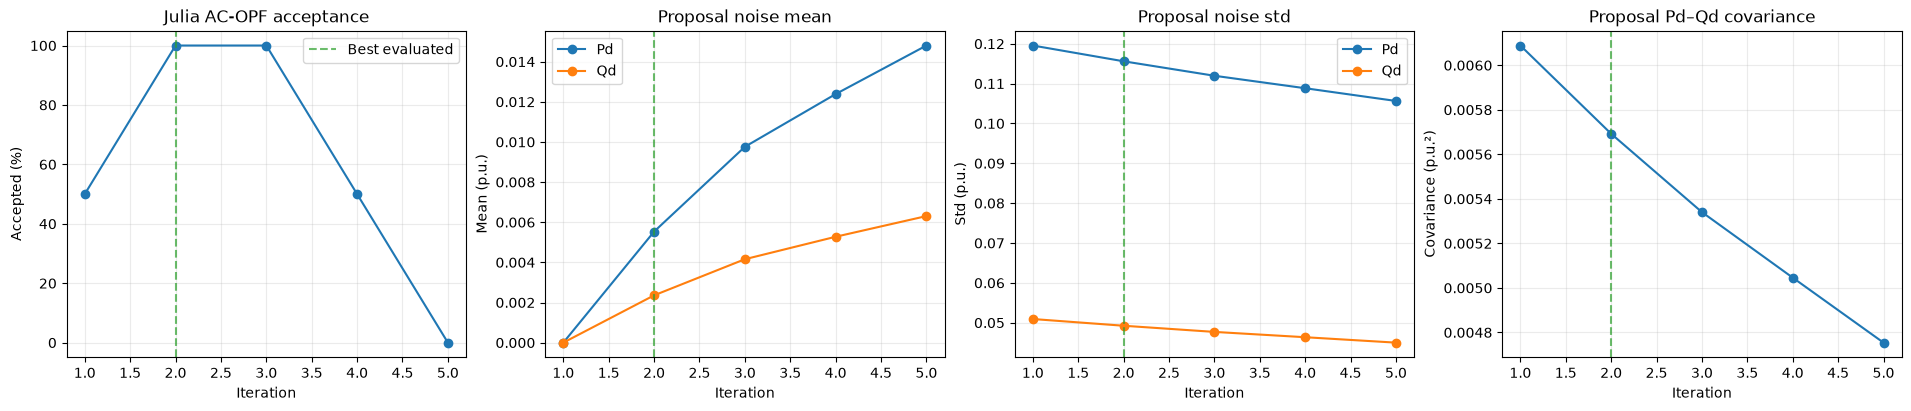

Best observed iteration: 2, acceptance: 100%
Restored mean: [0.00553258 0.00235668]
Restored std: [0.11559532 0.04924303]


In [22]:
if not history:
    print("No iterations to plot")
else:
    xs = [h["iteration"] for h in history]
    fig, axes = plt.subplots(1, 4, figsize=(19, 4), constrained_layout=True)
    axes[0].plot(xs, [100*h["acceptance_rate"] for h in history], marker="o")
    axes[0].set(title="Julia AC-OPF acceptance", xlabel="Iteration", ylabel="Accepted (%)", ylim=(-5, 105))
    for j, name in enumerate(["Pd", "Qd"]):
        axes[1].plot(xs, [h["proposal_noise_mu"][j] for h in history],
                     marker="o", label=name)
        axes[2].plot(xs, [h["proposal_noise_std"][j] for h in history],
                     marker="o", label=name)
    axes[1].set(title="Proposal noise mean", xlabel="Iteration", ylabel="Mean (p.u.)")
    axes[2].set(title="Proposal noise std", xlabel="Iteration", ylabel="Std (p.u.)")
    axes[3].plot(xs, [h["proposal_noise_cov"][0, 1] for h in history], marker="o")
    axes[3].set(title="Proposal Pd–Qd covariance", xlabel="Iteration", ylabel="Covariance (p.u.²)")
    for ax in axes:
        ax.axvline(best_iteration, color="tab:green", ls="--", alpha=0.7,
                   label="Best evaluated" if ax is axes[0] else None)
        ax.grid(alpha=0.25)
    axes[0].legend()
    axes[1].legend()
    axes[2].legend()
    plt.show()
    print(f"Best observed iteration: {best_iteration}, acceptance: {best_rate:.0%}")
    print("Restored mean:", best_noise_mu)
    print("Restored std:", np.sqrt(np.diag(best_noise_cov)))


## 10. Plot original loads vs. **fresh best-Gaussian** samples

The scatter shows up to 3,000 Pd/Qd load points from original data, from the freshly proposed explanation scenarios, and from their accepted subset. This uses the **best restored Gaussian**, not the final iteration's potentially worse proposal.


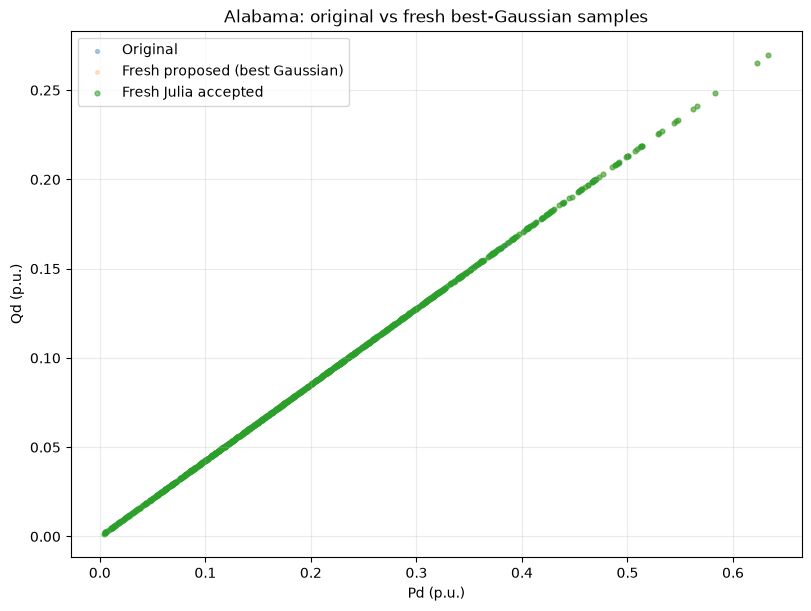

In [23]:
viz_rng = np.random.default_rng(123)
final_accepted_mask = np.asarray(best_explain_labels, dtype=bool)
final_accepted_loads = best_explain_candidates[final_accepted_mask]
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
for arr, label, size, transparency in [
    (loads, "Original", 8, 0.35),
    (best_explain_candidates.reshape(-1, 2), "Fresh proposed (best Gaussian)", 7, 0.2),
    (final_accepted_loads.reshape(-1, 2), "Fresh Julia accepted", 12, 0.55),
]:
    if len(arr) == 0:
        continue
    idx = viz_rng.choice(len(arr), size=min(3000, len(arr)), replace=False)
    pts = arr[idx]
    ax.scatter(pts[:, 0], pts[:, 1], s=size, alpha=transparency,
               label=label, rasterized=True)
ax.set(title=f"{DATASET_LABEL}: original vs fresh best-Gaussian samples",
       xlabel="Pd (p.u.)", ylabel="Qd (p.u.)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## 11. Export logs and inspect the new explanation dataset

Export a CSV containing all *training* verifier results, a CSV of the Gaussian proposal/updates per iteration, and a CSV of the *fresh* best-Gaussian verification results. The original `acopf_labeled_scenarios.npz` schema remains compatible with your existing explanation workflow; the new `acopf_best_gaussian_explanations.npz` is a separate, out-of-sample dataset.


In [24]:
log_path = OUTPUT_DIR / "verification_log.csv"
with log_path.open("w", newline="", encoding="utf-8") as f:
    cols = ["iteration", "scenario", "accepted", "status", "termination_status",
            "primal_status", "objective", "solve_time", "elapsed_s", "reason",
            "pd_change_pct", "qd_change_pct", "mean_abs_pd_change",
            "mean_abs_qd_change", "negative_pd", "negative_qd"]
    writer = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
    writer.writeheader()
    writer.writerows(verification_log)

history_path = OUTPUT_DIR / "sampling_history.csv"
with history_path.open("w", newline="", encoding="utf-8") as f:
    cols = ["iteration", "accepted_count", "rejected_count", "acceptance_rate",
            "updated", "is_best", "no_improve", "total_pairs", "initial_invalid_pairs",
            "resampling_rounds", "redrawn_pairs_total", "negative_pd_after", "negative_qd_after",
            "proposal_mu_pd", "proposal_mu_qd", "proposal_std_pd", "proposal_std_qd",
            "updated_mu_pd", "updated_mu_qd", "updated_std_pd", "updated_std_qd"]
    writer = csv.DictWriter(f, fieldnames=cols)
    writer.writeheader()
    for h in history:
        writer.writerow({
            **{k: h[k] for k in cols if k in h},
            "proposal_mu_pd": float(h["proposal_noise_mu"][0]),
            "proposal_mu_qd": float(h["proposal_noise_mu"][1]),
            "proposal_std_pd": float(h["proposal_noise_std"][0]),
            "proposal_std_qd": float(h["proposal_noise_std"][1]),
            "updated_mu_pd": float(h["noise_mu"][0]),
            "updated_mu_qd": float(h["noise_mu"][1]),
            "updated_std_pd": float(h["noise_std"][0]),
            "updated_std_qd": float(h["noise_std"][1]),
        })

fresh_log_path = OUTPUT_DIR / "best_explanation_verification_log.csv"
with fresh_log_path.open("w", newline="", encoding="utf-8") as f:
    cols = ["scenario", "accepted", "status", "termination_status", "primal_status",
            "objective", "solve_time", "elapsed_s", "reason", "pd_change_pct", "qd_change_pct"]
    writer = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
    writer.writeheader()
    writer.writerows(best_explain_log)

print("Training verification log:", log_path)
print("Gaussian history:", history_path)
print("Fresh verification log:", fresh_log_path)
print("Training scenarios:", SCENARIO_PATH)
print("Best parameters:", BEST_PARAMS_PATH)
print("Fresh explanation scenarios:", BEST_EXPLAIN_PATH)

# Example: arrays for Notebook 2, SHAP or Captum. No solver call here.
with np.load(BEST_EXPLAIN_PATH, allow_pickle=False) as saved:
    X_explain = saved["candidates"]  # (n_scenarios, n_loads, 2)
    y_explain = saved["accepted"]    # 1 if accepted, 0 otherwise
    print("Fresh explanation candidates:", X_explain.shape)
    print("Fresh accepted:", int(y_explain.sum()), "/", len(y_explain))
    print("Best mean:", saved["noise_mu"])
    print("Best std:", saved["noise_std"])


Training verification log: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/verification_log.csv
Gaussian history: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/sampling_history.csv
Fresh verification log: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/best_explanation_verification_log.csv
Training scenarios: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/acopf_labeled_scenarios.npz
Best parameters: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/best_gaussian_parameters.npz
Fresh explanation scenarios: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/acopf_best_gaussian_explanations.npz
Fresh explanation candidates: (2, 494, 2)
Fresh accepted: 2 / 2
Best mean: [0.00553258 0.00235668]
Best std: [0.11559532 0.04924303]


## Handoff to Notebook 2 — GridSFM and SHAP/Captum

Two compatible, but distinct, scenario archives are now available in `results/gaussian_load_centered/<dataset>/`:

- **`acopf_labeled_scenarios.npz`**: all adaptive-training proposals and their verifier outcomes, saved after each training iteration. Existing downstream notebooks can keep reading this unchanged format.
- **`acopf_best_gaussian_explanations.npz`**: **new**, independently drawn from the best observed Gaussian and labeled by Julia AC-OPF. Use this file when you want fresh scenarios for explainability. It includes `candidates`, `accepted`, `load_ids`, `dataset_name`, `source_case_sha256`, solver statuses, noise, and restored Gaussian parameters.

To inspect the fresh archive: `np.load(BEST_EXPLAIN_PATH, allow_pickle=False)` and read `candidates` and `accepted`. The Julia solver has already labeled the batch; Notebook 2 should not need to solve it again.

**Caveats:** `accepted=0` means *not verified/accepted* and can include solver failures, not only mathematically infeasible grids. SHAP/Captum explains **a predictive model**, not the Julia optimization solver directly. If your next notebook hardcodes the old filename, change its input path to `acopf_best_gaussian_explanations.npz`. The observed best acceptance rate is based on a limited training batch and can differ on fresh data.
